# Loss Visualization from TensorBoard

This notebook loads training losses from the latest TensorBoard run and visualizes:
1. Raw losses for streams A and B with smoothed versions
2. EMA losses for streams A and B (raw only)


In [18]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing import event_accumulator
from pathlib import Path

import pandas as pd

# Set plot style
plt.style.use('default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 10


## Load TensorBoard Data


In [19]:
def get_latest_run(tensorboard_dir='./tensorboard_logs'):
    """Find the latest run directory in tensorboard logs."""
    runs = [d for d in Path(tensorboard_dir).iterdir() if d.is_dir()]
    if not runs:
        raise ValueError(f"No runs found in {tensorboard_dir}")
    latest_run = max(runs, key=lambda x: x.stat().st_mtime)
    return latest_run

def load_tensorboard_scalars(log_dir, tags):
    """Load scalar data from TensorBoard event files."""
    ea = event_accumulator.EventAccumulator(str(log_dir))
    ea.Reload()
    
    data = {}
    for tag in tags:
        if tag in ea.Tags()['scalars']:
            events = ea.Scalars(tag)
            steps = [e.step for e in events]
            values = [e.value for e in events]
            data[tag] = {'steps': np.array(steps), 'values': np.array(values)}
        else:
            print(f"Warning: Tag '{tag}' not found in logs")
    
    return data

def smooth_values(values, window=50):
    """Apply moving average smoothing to values."""
    if len(values) < window:
        window = max(1, len(values) // 2)
    
    smoothed = np.convolve(values, np.ones(window) / window, mode='valid')
    # Pad to match original length
    pad_left = (len(values) - len(smoothed)) // 2
    pad_right = len(values) - len(smoothed) - pad_left
    smoothed = np.pad(smoothed, (pad_left, pad_right), mode='edge')
    
    return smoothed


In [20]:
# Find and load data from the latest run
latest_run = get_latest_run()
print(f"Loading data from: {latest_run}")



# Define tags to load
tags = ['train/loss_A', 'train/loss_B', 'train/loss_total', 'train/ema_loss_A', 'train/ema_loss_B']

# Load data
data = load_tensorboard_scalars(latest_run, tags)

print(f"\nLoaded {len(data)} metrics:")
for tag, values in data.items():
    print(f"  {tag}: {len(values['steps'])} data points")


Loading data from: tensorboard_logs/run_20251011_215217

Loaded 5 metrics:
  train/loss_A: 10000 data points
  train/loss_B: 10000 data points
  train/loss_total: 10000 data points
  train/ema_loss_A: 10000 data points
  train/ema_loss_B: 10000 data points


## Visualize Raw and Smoothed Losses


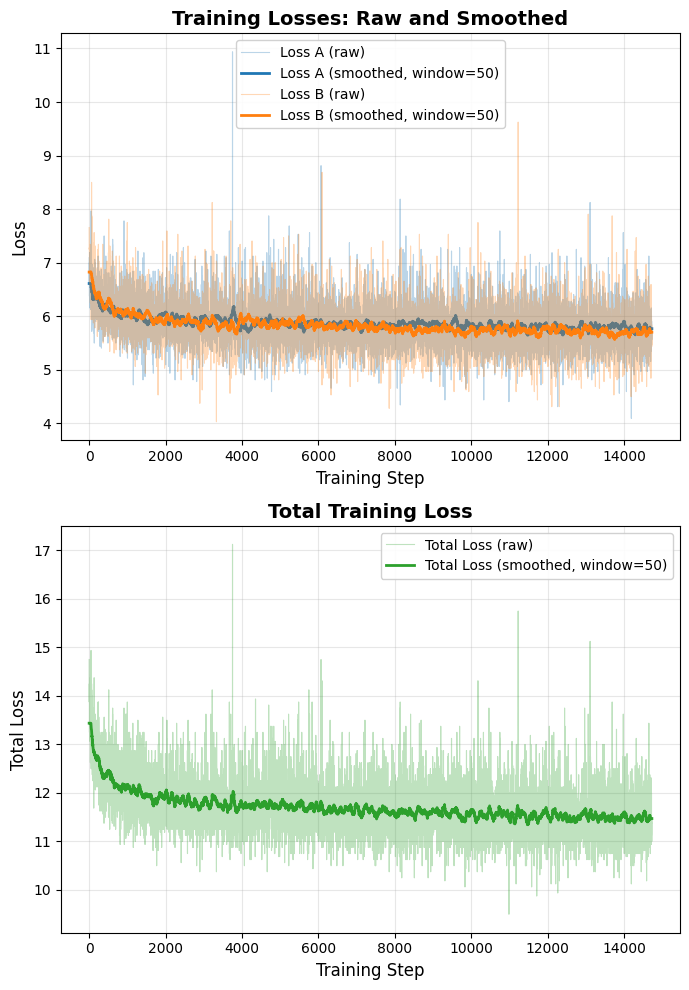

In [21]:
# Set smoothing window size
smoothing_window = 50

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 10))

# Colors for streams A and B
color_A = '#1f77b4'  # Blue
color_B = '#ff7f0e'  # Orange
color_total = '#2ca02c'  # Green

# Plot Loss A and B in first subplot
if 'train/loss_A' in data:
    steps_A = data['train/loss_A']['steps']
    values_A = data['train/loss_A']['values']
    smoothed_A = smooth_values(values_A, window=smoothing_window)
    
    # Raw (pale)
    ax1.plot(steps_A, values_A, color=color_A, alpha=0.3, linewidth=0.8, label='Loss A (raw)')
    # Smoothed (bright)
    ax1.plot(steps_A, smoothed_A, color=color_A, alpha=1.0, linewidth=2.0, label=f'Loss A (smoothed, window={smoothing_window})')

if 'train/loss_B' in data:
    steps_B = data['train/loss_B']['steps']
    values_B = data['train/loss_B']['values']
    smoothed_B = smooth_values(values_B, window=smoothing_window)
    
    # Raw (pale)
    ax1.plot(steps_B, values_B, color=color_B, alpha=0.3, linewidth=0.8, label='Loss B (raw)')
    # Smoothed (bright)
    ax1.plot(steps_B, smoothed_B, color=color_B, alpha=1.0, linewidth=2.0, label=f'Loss B (smoothed, window={smoothing_window})')

ax1.set_xlabel('Training Step', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.set_title('Training Losses: Raw and Smoothed', fontsize=14, fontweight='bold')
ax1.legend(loc='best', framealpha=0.9)
ax1.grid(True, alpha=0.3)

# Plot total loss in second subplot
if 'train/loss_total' in data:
    steps_total = data['train/loss_total']['steps']
    values_total = data['train/loss_total']['values']
    smoothed_total = smooth_values(values_total, window=smoothing_window)
    
    # Raw (pale)
    ax2.plot(steps_total, values_total, color=color_total, alpha=0.3, linewidth=0.8, label='Total Loss (raw)')
    # Smoothed (bright)
    ax2.plot(steps_total, smoothed_total, color=color_total, alpha=1.0, linewidth=2.0, label=f'Total Loss (smoothed, window={smoothing_window})')

ax2.set_xlabel('Training Step', fontsize=12)
ax2.set_ylabel('Total Loss', fontsize=12)
ax2.set_title('Total Training Loss', fontsize=14, fontweight='bold')
ax2.legend(loc='best', framealpha=0.9)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


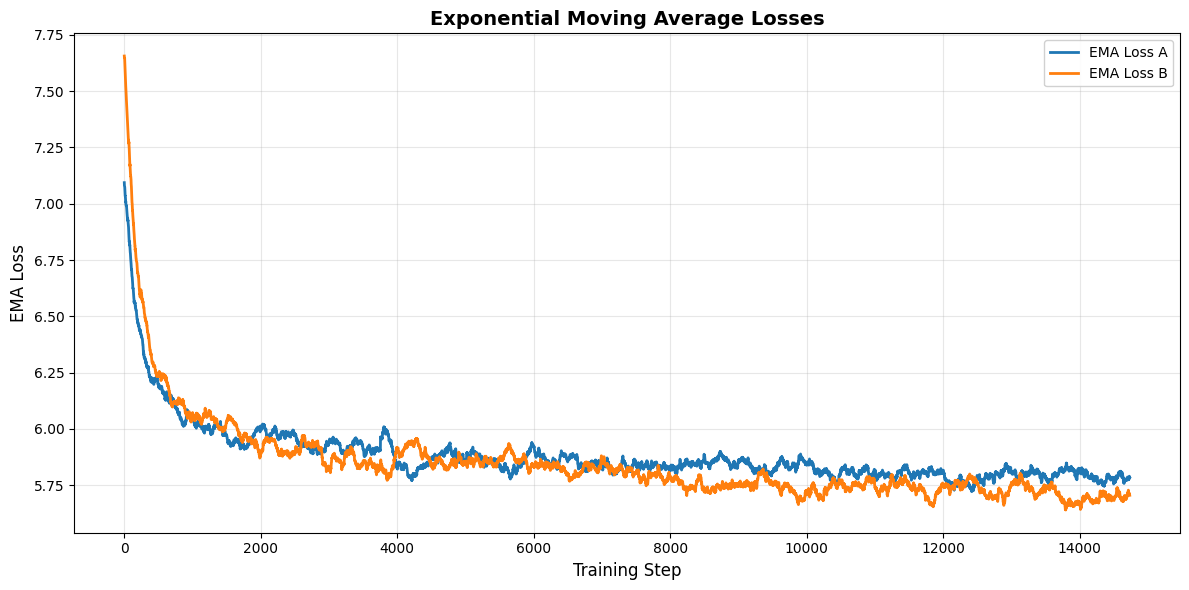

In [ ]:
# Create figure for EMA losses
fig, ax = plt.subplots(1, 1, figsize=(12, 6))

# Plot EMA Loss A
if 'train/ema_loss_A' in data:
    steps_ema_A = data['train/ema_loss_A']['steps']
    values_ema_A = data['train/ema_loss_A']['values']
    ax.plot(steps_ema_A, values_ema_A, color=color_A, linewidth=2.0, label='EMA Loss A')

# Plot EMA Loss B
if 'train/ema_loss_B' in data:
    steps_ema_B = data['train/ema_loss_B']['steps']
    values_ema_B = data['train/ema_loss_B']['values']
    ax.plot(steps_ema_B, values_ema_B, color=color_B, linewidth=2.0, label='EMA Loss B')

ax.set_xlabel('Training Step', fontsize=12)
ax.set_ylabel('EMA Loss', fontsize=12)
ax.set_title('Exponential Moving Average Losses', fontsize=14, fontweight='bold')
ax.legend(loc='best', framealpha=0.9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Alpha and Beta Coefficients (Latest Run)


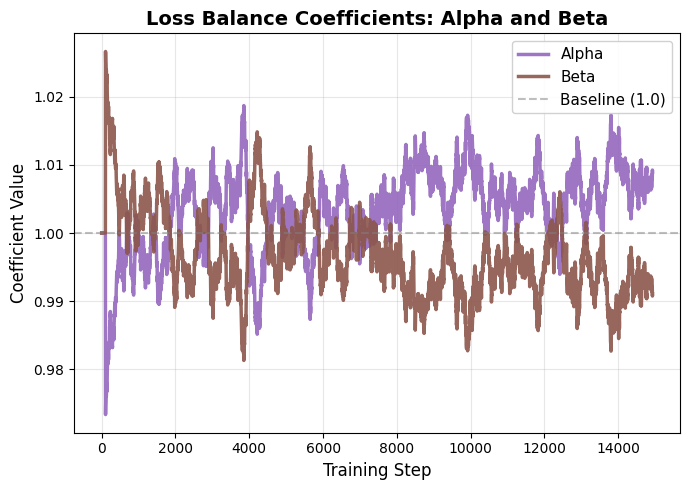

Alpha range: [0.9734, 1.0187]
Beta range: [0.9813, 1.0266]
Final alpha: 1.0089
Final beta: 0.9911


In [29]:
# Load alpha and beta data from the latest run
alpha_beta_tags = ['loss_balance/alpha', 'loss_balance/beta']
alpha_beta_data = load_tensorboard_scalars(latest_run, alpha_beta_tags)

if 'loss_balance/alpha' in alpha_beta_data and 'loss_balance/beta' in alpha_beta_data:
    # Create figure
    fig, ax = plt.subplots(1, 1, figsize=(7, 5))
    
    # Colors for alpha and beta
    color_alpha = '#9467bd'  # Purple
    color_beta = '#8c564b'   # Brown
    
    # Plot Alpha
    steps_alpha = alpha_beta_data['loss_balance/alpha']['steps']
    values_alpha = alpha_beta_data['loss_balance/alpha']['values']
    ax.plot(steps_alpha, values_alpha, color=color_alpha, linewidth=2.5, label='Alpha', alpha=0.9)
    
    # Plot Beta
    steps_beta = alpha_beta_data['loss_balance/beta']['steps']
    values_beta = alpha_beta_data['loss_balance/beta']['values']
    ax.plot(steps_beta, values_beta, color=color_beta, linewidth=2.5, label='Beta', alpha=0.9)
    
    # Add baseline line at 1.0
    ax.axhline(y=1.0, color='gray', linestyle='--', linewidth=1.5, alpha=0.5, label='Baseline (1.0)')
    
    ax.set_xlabel('Training Step', fontsize=12)
    ax.set_ylabel('Coefficient Value', fontsize=12)
    ax.set_title('Loss Balance Coefficients: Alpha and Beta', fontsize=14, fontweight='bold')
    ax.legend(loc='best', framealpha=0.9, fontsize=11)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print(f"Alpha range: [{values_alpha.min():.4f}, {values_alpha.max():.4f}]")
    print(f"Beta range: [{values_beta.min():.4f}, {values_beta.max():.4f}]")
    print(f"Final alpha: {values_alpha[-1]:.4f}")
    print(f"Final beta: {values_beta[-1]:.4f}")
else:
    print("Warning: Alpha and Beta data not found in the latest run")


## Case Study: `run_20251011_052831` (Before Alpha/Beta Implementation)


In [ ]:
# Load data from the specific run before alpha/beta implementation
case_study_run = Path('./tensorboard_logs/run_20251011_052831')

if not case_study_run.exists():
    print(f"Warning: Run directory {case_study_run} not found")

else:
    print(f"Loading data from: {case_study_run}")
    
    # Load loss data
    case_tags = ['train/loss_A', 'train/loss_B', 'train/loss_total']
    case_data = load_tensorboard_scalars(case_study_run, case_tags)
    
    print(f"\nLoaded {len(case_data)} metrics:")
    for tag, values in case_data.items():
        print(f"  {tag}: {len(values['steps'])} data points")


Loading data from: tensorboard_logs/run_20251011_052831

Loaded 3 metrics:
  train/loss_A: 10000 data points
  train/loss_B: 10000 data points
  train/loss_total: 10000 data points


In [25]:
# Calculate what alpha and beta would have been with current implementation
def calculate_alpha_beta(loss_A_values, loss_B_values,
                         ema_momentum=0.99, 
                         strength=1.0,
                         warmup_steps=100,
                         clip_min=0.1,
                         clip_max=10.0):
    """
    Calculate alpha and beta coefficients as they would have been calculated
    during training with the current implementation.
    """
    alpha_history = []
    beta_history = []
    ema_loss_A_history = []
    ema_loss_B_history = []
    
    ema_loss_A = None
    ema_loss_B = None
    
    for step, (loss_A, loss_B) in enumerate(zip(loss_A_values, loss_B_values)):
        # Update EMA
        if ema_loss_A is None:
            ema_loss_A = loss_A
            ema_loss_B = loss_B
        else:
            ema_loss_A = ema_momentum * ema_loss_A + (1 - ema_momentum) * loss_A
            ema_loss_B = ema_momentum * ema_loss_B + (1 - ema_momentum) * loss_B
        
        ema_loss_A_history.append(ema_loss_A)
        ema_loss_B_history.append(ema_loss_B)
        
        # Calculate alpha and beta after warmup
        if step >= warmup_steps:
            total_loss = ema_loss_A + ema_loss_B
            weight_A = (ema_loss_A / total_loss) ** strength
            weight_B = (ema_loss_B / total_loss) ** strength
            
            # Normalize so alpha + beta = 2
            norm = weight_A + weight_B
            alpha = weight_A / norm * 2.0
            beta = weight_B / norm * 2.0
            
            # Apply clipping
            alpha = np.clip(alpha, clip_min, clip_max)
            beta = np.clip(beta, clip_min, clip_max)
        else:
            alpha = 1.0
            beta = 1.0
        
        alpha_history.append(alpha)
        beta_history.append(beta)
    
    return {
        'alpha': np.array(alpha_history),
        'beta': np.array(beta_history),
        'ema_loss_A': np.array(ema_loss_A_history),
        'ema_loss_B': np.array(ema_loss_B_history)
    }

if case_study_run.exists() and 'train/loss_A' in case_data and 'train/loss_B' in case_data:
    # Calculate alpha and beta
    coeffs = calculate_alpha_beta(
        case_data['train/loss_A']['values'],
        case_data['train/loss_B']['values']
    )
    
    print("Alpha and Beta calculation completed")
    print(f"  Alpha range: [{coeffs['alpha'].min():.4f}, {coeffs['alpha'].max():.4f}]")
    print(f"  Beta range: [{coeffs['beta'].min():.4f}, {coeffs['beta'].max():.4f}]")
    print(f"  Final alpha: {coeffs['alpha'][-1]:.4f}")
    print(f"  Final beta: {coeffs['beta'][-1]:.4f}")


Alpha and Beta calculation completed
  Alpha range: [0.9939, 1.1039]
  Beta range: [0.8961, 1.0061]
  Final alpha: 1.0948
  Final beta: 0.9052


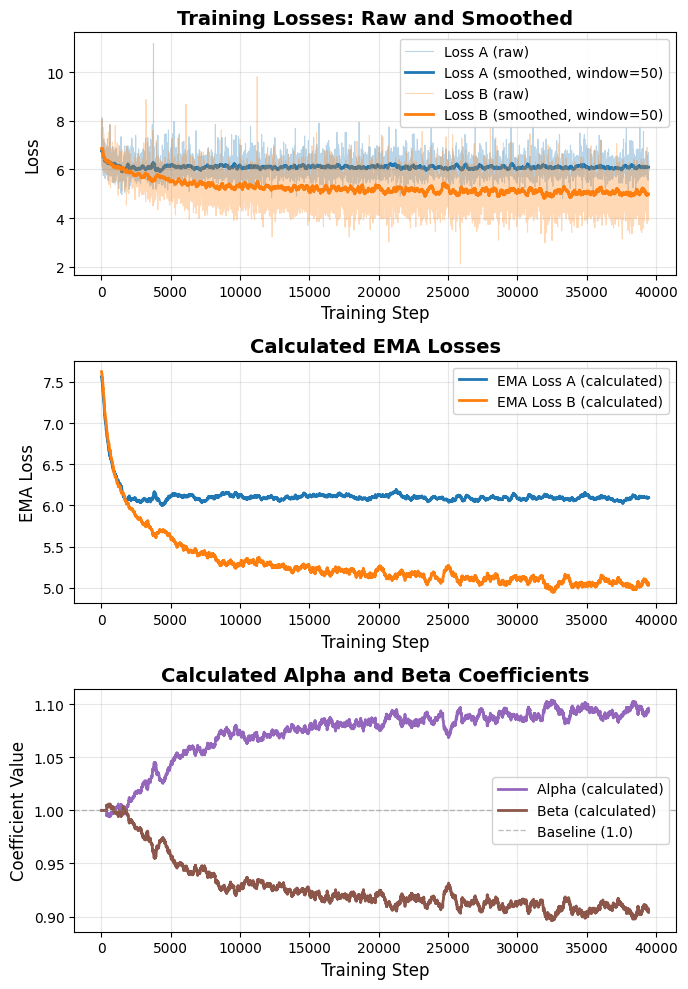

In [26]:
# Visualize losses for the case study run
if case_study_run.exists() and 'train/loss_A' in case_data:
    fig, axes = plt.subplots(3, 1, figsize=(7, 10))
    
    steps = case_data['train/loss_A']['steps']
    loss_A = case_data['train/loss_A']['values']
    loss_B = case_data['train/loss_B']['values']
    
    # Smooth the losses
    smoothed_A = smooth_values(loss_A, window=smoothing_window)
    smoothed_B = smooth_values(loss_B, window=smoothing_window)
    
    # Plot 1: Raw and smoothed losses
    axes[0].plot(steps, loss_A, color=color_A, alpha=0.3, linewidth=0.8, label='Loss A (raw)')
    axes[0].plot(steps, smoothed_A, color=color_A, alpha=1.0, linewidth=2.0, label=f'Loss A (smoothed, window={smoothing_window})')
    axes[0].plot(steps, loss_B, color=color_B, alpha=0.3, linewidth=0.8, label='Loss B (raw)')
    axes[0].plot(steps, smoothed_B, color=color_B, alpha=1.0, linewidth=2.0, label=f'Loss B (smoothed, window={smoothing_window})')
    
    axes[0].set_xlabel('Training Step', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    axes[0].set_title('Training Losses: Raw and Smoothed', fontsize=14, fontweight='bold')
    axes[0].legend(loc='best', framealpha=0.9)
    axes[0].grid(True, alpha=0.3)
    
    # Plot 2: Calculated EMA losses
    axes[1].plot(steps, coeffs['ema_loss_A'], color=color_A, linewidth=2.0, label='EMA Loss A (calculated)')
    axes[1].plot(steps, coeffs['ema_loss_B'], color=color_B, linewidth=2.0, label='EMA Loss B (calculated)')
    
    axes[1].set_xlabel('Training Step', fontsize=12)
    axes[1].set_ylabel('EMA Loss', fontsize=12)
    axes[1].set_title('Calculated EMA Losses', fontsize=14, fontweight='bold')
    axes[1].legend(loc='best', framealpha=0.9)
    axes[1].grid(True, alpha=0.3)
    
    # Plot 3: Calculated alpha and beta coefficients
    axes[2].plot(steps, coeffs['alpha'], color='#9467bd', linewidth=2.0, label='Alpha (calculated)')
    axes[2].plot(steps, coeffs['beta'], color='#8c564b', linewidth=2.0, label='Beta (calculated)')
    axes[2].axhline(y=1.0, color='gray', linestyle='--', linewidth=1.0, alpha=0.5, label='Baseline (1.0)')
    
    axes[2].set_xlabel('Training Step', fontsize=12)
    axes[2].set_ylabel('Coefficient Value', fontsize=12)
    axes[2].set_title('Calculated Alpha and Beta Coefficients', fontsize=14, fontweight='bold')
    axes[2].legend(loc='best', framealpha=0.9)
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
